# Operations DMAIC Case Study: Field-Service Tool Management & Loading Efficiency

**Privacy note:** This case study has been anonymized. The company name, owner name,
and employee names have been removed, and the business's location and calendar dates
have been generalized for public portfolio use. Quantified operational results
(percentages, hours, dollar estimates) are preserved from the original engagement, since
they represent the analytical content of this project and do not, on their own, identify
the business. See `NOTES.md` for the full list of what was changed.

A DMAIC (Define-Measure-Analyze-Improve-Control) process improvement case study for a
small, two-person field-service business — identifying and fixing chronic operational
waste in pre-job tool preparation using standard Lean Six Sigma tools, entirely reproducible
in Python from a small aggregated results dataset (no proprietary business data required).


## Define

**Business context:** the Company is a small regional landscaping and tree-service
business (two field workers, two vehicles) providing tree trimming/removal, outdoor
lighting installation, and general landscaping services in a mid-sized U.S. metro area.

**Problem statement:** the Company had no standardized tool management or pre-job
preparation process. Tools were stored without organization, job preparation relied
entirely on memory, and forgotten tools caused frequent field delays. A DMAIC + 5S
(Sort, Set in Order, Shine, Standardize, Sustain) project was scoped to address this.

**Goal statement:** reduce wasted field time, materials cost, and job execution errors
by standardizing pre-job planning and tool loading — without adding new software,
headcount, or capital investment, since the business operates as a lean, two-person,
tablet-only operation.

**Project scope:**
- Tool storage and loading process at the operating base
- Client estimate intake and remote job commitment protocol
- Worker scheduling and synchronized start times
- Materials and supply management by job type


## Measure

Baselines were established using attribute-based observation (checklist present/absent,
loading time, tool correctness, gate-code availability, start-time alignment), collected
through direct observation, an owner interview, and a review of truck/storage contents.
A formal Gauge R&R study wasn't appropriate given the attribute- and time-based
measurement approach; consistency was instead ensured by defining each metric in writing
before data collection began and using the same paper form for every observation.

### Data Loading


In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrow
import os

plt.rcParams["figure.dpi"] = 110
IMAGES_DIR = "images"
os.makedirs(IMAGES_DIR, exist_ok=True)

kpi = pd.read_csv("data/kpi_summary.csv")
cost = pd.read_csv("data/annual_cost_impact.csv")
kpi

,KPI,Baseline,Target_Or_Result,Unit,Improvement_Pct
0,Average Tool Loading Time,10.38,5.57,minutes,46.3
1,Forgotten Tool Incidents per Week,3.50,0.50,incidents,85.7
2,Process Defect Rate,23.30,3.30,percent,85.8
3,Process Sigma Level,2.20,3.30,sigma,50.0


In [2]:
cost

,Root_Cause_Category,Estimated_Annual_Cost_USD,Basis
0,Unpaid early-arrival loading labor,3384,188 hrs/yr x $18/hr labor rate (45 min/job x ~...
1,Wasted remote-estimate trips,2178,Midpoint of $1452-$2904/yr range (confirmed $1...
2,Forgotten-tool field delays,2700,Midpoint of 100-200 hrs/yr field delay x $18/h...
3,Uncontrolled tool loading time,1404,78 hrs/yr excess loading time x $18/hr labor rate
4,Duplicate tool/material purchases,340,20+ duplicate chainsaw chains confirmed at $17...


### Data Quality Check

Both files are small, manually compiled summary tables (not raw transactional data), so
the checks here are simple completeness and range checks rather than a large-scale
missing-value/duplicate audit.


In [3]:
print("KPI summary — missing values:", kpi.isna().sum().sum(), " | rows:", len(kpi))
print("Cost impact — missing values:", cost.isna().sum().sum(), " | rows:", len(cost))
print()
print("KPI improvement range check (all should be between 0-100%):")
print(kpi["Improvement_Pct"].between(0, 100).all())

KPI summary — missing values: 0  | rows: 4
Cost impact — missing values: 0  | rows: 5

KPI improvement range check (all should be between 0-100%):
True


### Baseline sigma level

Because this project measures a service process using attribute (defect/no-defect) data
rather than continuous measurement data, traditional Cpk/Ppk indices don't apply. A
sigma level (Z) was estimated from Defects Per Million Opportunities (DPMO), based on the
observed forgotten-tool defect rate (~15 job departures/week, 3-4 forgotten-tool
incidents/week baseline).


In [4]:
baseline_defect_rate = 23.3   # % — from Measure phase
target_defect_rate = 3.3      # % — after Improve phase
baseline_dpmo = baseline_defect_rate / 100 * 1_000_000
target_dpmo = target_defect_rate / 100 * 1_000_000
print(f"Baseline DPMO: {baseline_dpmo:,.0f}  (~2.2 sigma)")
print(f"Target DPMO:   {target_dpmo:,.0f}  (~3.3 sigma)")

Baseline DPMO: 233,000  (~2.2 sigma)
Target DPMO:   33,000  (~3.3 sigma)


### Process timeline

The engagement ran as a sequential-but-overlapping DMAIC cycle over roughly four months.


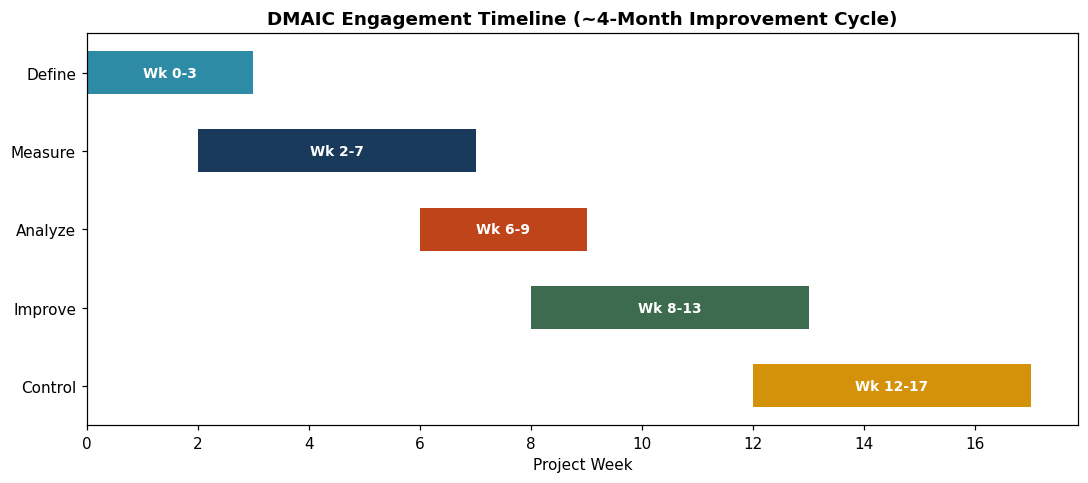

In [5]:
phases = [
    ("Define",  0, 3),
    ("Measure", 2, 7),
    ("Analyze", 6, 9),
    ("Improve", 8, 13),
    ("Control", 12, 17),
]
colors = ["#2E8BA5", "#1A3A5C", "#C0441A", "#3D6B4F", "#D4920A"]

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, (name, start, end) in enumerate(phases):
    ax.barh(name, end - start, left=start, color=colors[i], height=0.55)
    ax.text(start + (end - start) / 2, i, f"Wk {start}-{end}", ha="center", va="center",
            color="white", fontweight="bold", fontsize=9)
ax.set_xlabel("Project Week")
ax.set_title("DMAIC Engagement Timeline (~4-Month Improvement Cycle)", fontweight="bold")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/process-timeline.png", dpi=150)
plt.show()

## Analyze

Fishbone (Ishikawa) diagramming, 5 Whys, and Pareto-style prioritization were used to
isolate the vital few root causes driving the project's primary metric (wasted field
time). Root causes were found to be exclusively process-design gaps — not employee
effort, demand variability, or equipment reliability — which is what made a low-cost,
low-tech 5S intervention appropriate rather than a staffing or capital investment.

### Root cause categories (fishbone analysis)


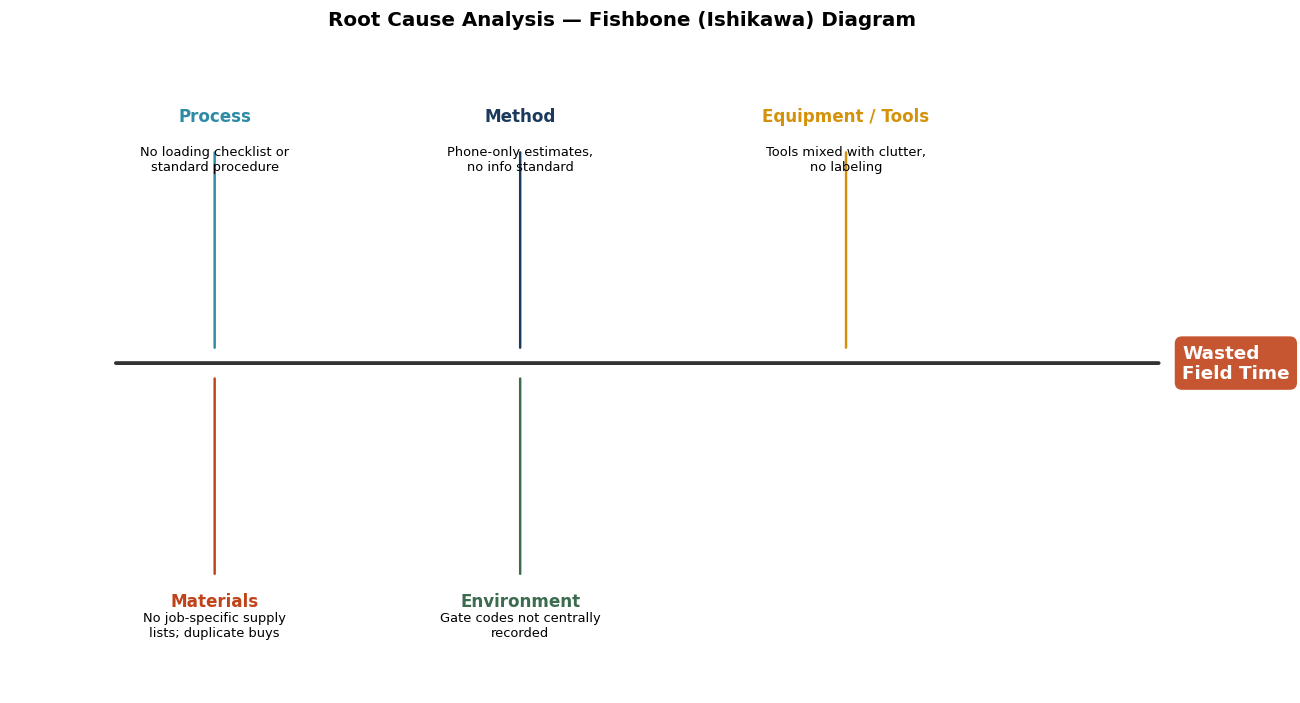

In [6]:
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

# spine
ax.annotate("", xy=(11.3, 4), xytext=(1, 4), arrowprops=dict(arrowstyle="-", lw=2.5, color="#333"))
ax.text(11.5, 4, "Wasted\nField Time", fontsize=12, fontweight="bold", va="center",
        bbox=dict(boxstyle="round,pad=0.4", fc="#C0441A", ec="none", alpha=0.9), color="white")

causes = {
    "Process":   ("No loading checklist or\nstandard procedure", 2.0, 6.6, 1),
    "Method":    ("Phone-only estimates,\nno info standard", 5.0, 6.6, 1),
    "Materials": ("No job-specific supply\nlists; duplicate buys", 2.0, 1.4, -1),
    "Environment": ("Gate codes not centrally\nrecorded", 5.0, 1.4, -1),
    "Equipment / Tools": ("Tools mixed with clutter,\nno labeling", 8.2, 6.6, 1),
}

for label, (desc, x, y, direction) in causes.items():
    branch_x_end = x
    ax.annotate("", xy=(branch_x_end, 4 + 0.15*direction), xytext=(x, y),
                arrowprops=dict(arrowstyle="-", lw=1.6, color=colors[list(causes).index(label) % len(colors)]))
    ax.text(x, y + (0.35 if direction > 0 else -0.35), label, fontsize=11, fontweight="bold",
            ha="center", color=colors[list(causes).index(label) % len(colors)])
    ax.text(x, y + (0.05 if direction > 0 else -0.75) , desc, fontsize=8.5, ha="center", va="top" if direction>0 else "bottom")

ax.set_title("Root Cause Analysis — Fishbone (Ishikawa) Diagram", fontweight="bold", fontsize=13)
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/root-cause-fishbone.png", dpi=150)
plt.show()

### Pareto prioritization by estimated annual cost impact

Each root-cause category was prioritized because it was fully controllable, required no
new technology, and connected directly to an observable cost. Hour-based estimates are
converted to dollars using the same $18/hr labor rate used elsewhere in this analysis, so
all five categories are comparable on one axis.


/var/folders/yj/6syp88kd71q5pwb4b4rytzs80000gn/T/ipykernel_68762/2042708662.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(cost_sorted["Root_Cause_Category"], rotation=30, ha="right")


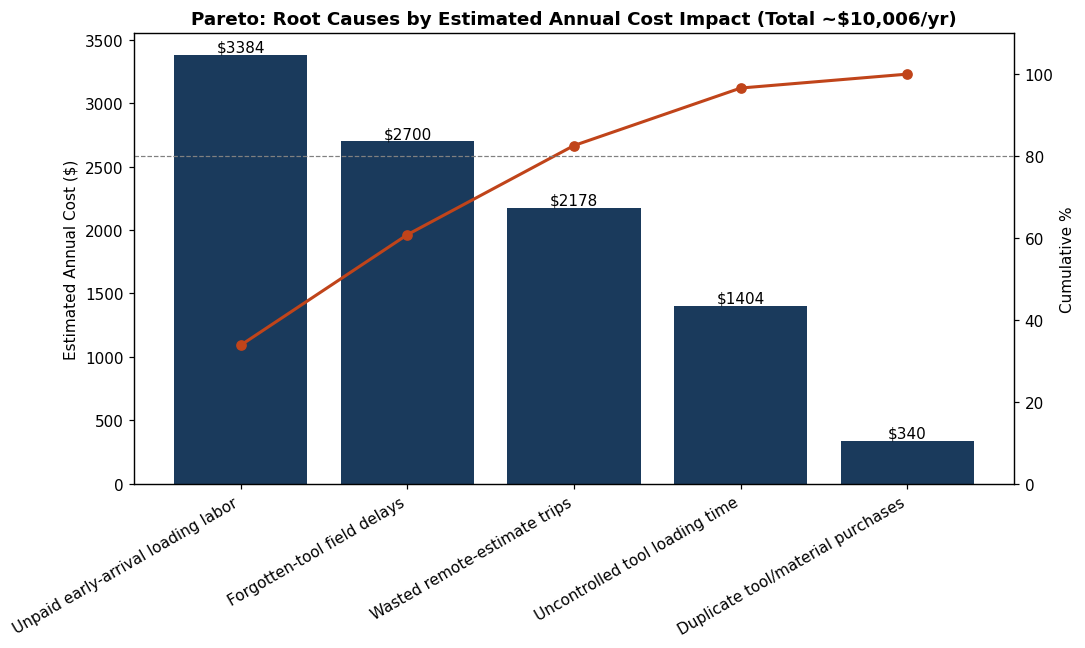

In [7]:
cost_sorted = cost.sort_values("Estimated_Annual_Cost_USD", ascending=False).reset_index(drop=True)
cost_sorted["Cumulative_Pct"] = cost_sorted["Estimated_Annual_Cost_USD"].cumsum() / cost_sorted["Estimated_Annual_Cost_USD"].sum() * 100

fig, ax1 = plt.subplots(figsize=(10, 6))
bars = ax1.bar(cost_sorted["Root_Cause_Category"], cost_sorted["Estimated_Annual_Cost_USD"], color="#1A3A5C")
ax1.set_ylabel("Estimated Annual Cost ($)")
ax1.set_xticklabels(cost_sorted["Root_Cause_Category"], rotation=30, ha="right")
ax1.bar_label(bars, fmt="$%.0f")

ax2 = ax1.twinx()
ax2.plot(cost_sorted["Root_Cause_Category"], cost_sorted["Cumulative_Pct"], color="#C0441A",
         marker="o", linewidth=2)
ax2.set_ylabel("Cumulative %")
ax2.set_ylim(0, 110)
ax2.axhline(80, color="grey", linestyle="--", linewidth=0.8)

total = cost_sorted["Estimated_Annual_Cost_USD"].sum()
ax1.set_title(f"Pareto: Root Causes by Estimated Annual Cost Impact (Total ~${total:,.0f}/yr)", fontweight="bold")
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/issue-frequency-pareto.png", dpi=150)
plt.show()

## Improve

All solutions were constrained to work within a low-tech, two-person operation: no
scheduling software, no new hires, no capital investment. Alternatives considered and
rejected included field-service scheduling software (added cost and workflow overhead
not aligned with the owner's preference), a full inventory management system
(overkill for a two-person team's job-readiness problem), and adding a vehicle or
staff (would have scaled the existing waste rather than fixing it).

**What was implemented (5S):**
- **Sort** — separated tools from clutter across the storage area; this pass is what
  surfaced the duplicate tool inventory.
- **Set in Order** — color-coded tool labeling by job type, labeled storage zones,
  laminated visual reference guides.
- **Standardize** — two vehicle binders (one per truck) with job-specific checklists, an
  estimate checklist, and a gate-code reference sheet.
- **Sustain** — in-person training on the full system for both workers.

A standardized estimate protocol was also introduced: any job more than ~45 minutes from
base now requires a photo or video from the client before a commitment is made, directly
targeting the wasted-trip root cause.

### Before / after KPI comparison


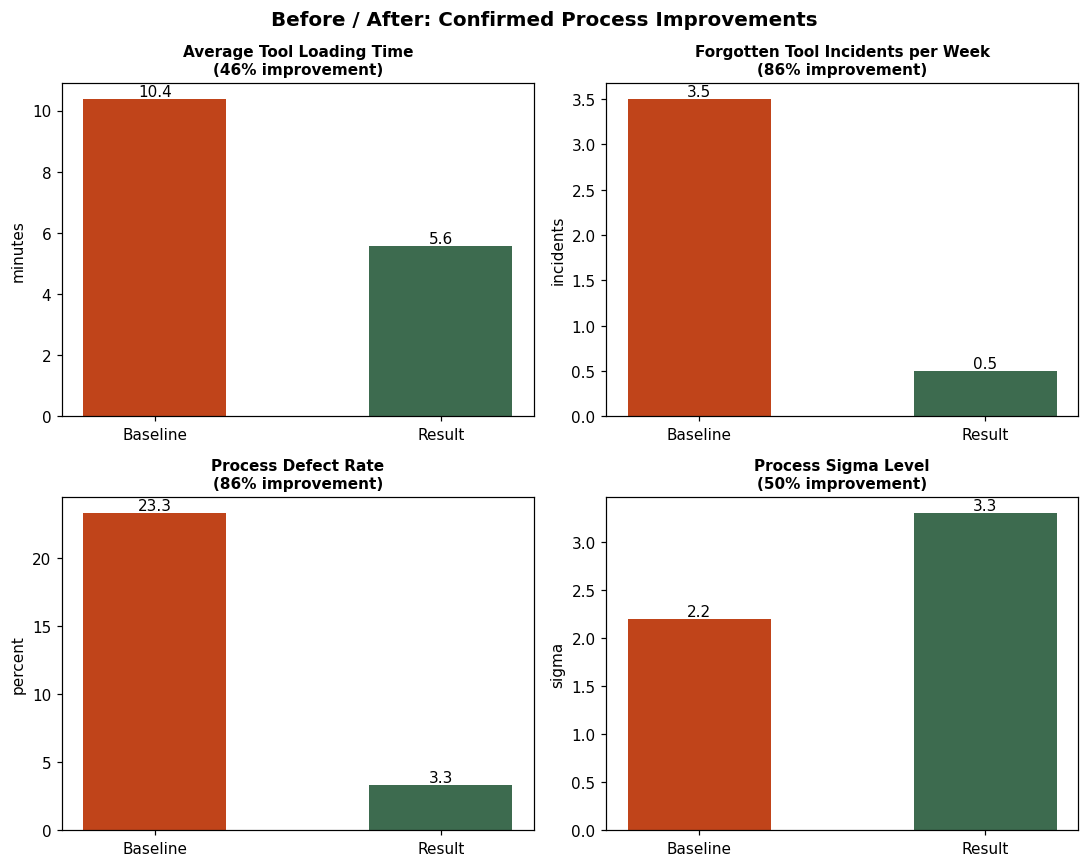

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
kpi_plot = kpi.set_index("KPI")

for ax, (idx, row) in zip(axes.flat, kpi_plot.iterrows()):
    bars = ax.bar(["Baseline", "Result"], [row["Baseline"], row["Target_Or_Result"]],
                   color=["#C0441A", "#3D6B4F"], width=0.5)
    ax.bar_label(bars, fmt="%.1f")
    ax.set_title(f"{idx}\n({row['Improvement_Pct']:.0f}% improvement)", fontsize=10, fontweight="bold")
    ax.set_ylabel(row["Unit"])

fig.suptitle("Before / After: Confirmed Process Improvements", fontweight="bold", fontsize=13)
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/before-after-kpi-comparison.png", dpi=150)
plt.show()

## Control

Controls are embedded at the point of work — inside the vehicles, at the storage area,
and during a weekly review — so sustaining the new process requires no extra
administrative step that could lapse under time pressure.


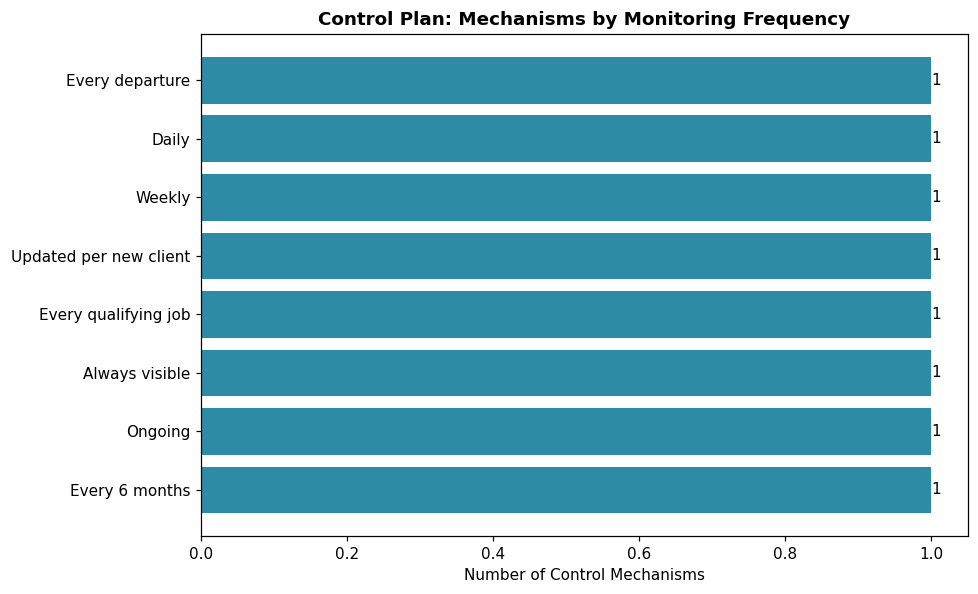

In [9]:
control_mechanisms = pd.DataFrame({
    "Mechanism": [
        "Laminated job checklists", "Color-coded tool labeling", "Photo reference guide",
        "Gate-code binder", "Weekly incident log", "Checklist content refresh",
        "Remote estimate compliance", "Synchronized start time"
    ],
    "Frequency": [
        "Every departure", "Ongoing", "Always visible", "Updated per new client",
        "Weekly", "Every 6 months", "Every qualifying job", "Daily"
    ]
})

freq_order = ["Every departure", "Daily", "Weekly", "Updated per new client",
              "Every qualifying job", "Always visible", "Ongoing", "Every 6 months"]
freq_counts = control_mechanisms["Frequency"].value_counts().reindex(freq_order).fillna(0)

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(freq_counts.index[::-1], freq_counts.values[::-1], color="#2E8BA5")
ax.bar_label(bars, fmt="%.0f")
ax.set_xlabel("Number of Control Mechanisms")
ax.set_title("Control Plan: Mechanisms by Monitoring Frequency", fontweight="bold")
fig.tight_layout()
fig.savefig(f"{IMAGES_DIR}/control-plan-summary.png", dpi=150)
plt.show()

## Findings

- **Loading time dropped ~46%** (10.4 min → 5.6 min per departure) — a direct result of
  color-coded tool labeling and a laminated pre-job checklist, requiring no new tools or
  headcount.
- **Forgotten-tool incidents dropped ~86%** (3.5/week baseline → 0.5/week), correspondingly
  dropping the estimated process defect rate from 23.3% to 3.3% and moving the estimated
  process sigma level from ~2.2σ to ~3.3σ.
- **Sorting the storage area alone surfaced $340+ in duplicate tool purchases**
  (20+ duplicate chainsaw chains) — a pure byproduct of disorganization, recovered at
  zero additional cost as part of the 5S "Sort" step.
- **The single largest cost driver was unpaid early-arrival labor** (~$3,400/yr
  estimated), not any of the more visible symptoms like forgotten tools — this only
  became visible once the root-cause analysis moved past "what's annoying" to "what's
  actually costing money."
- **All identified root causes were process-design gaps, not effort or equipment
  problems** — this is what made a $40, no-software intervention appropriate; a
  higher-tech or higher-cost fix would have been solving the wrong problem.


## Recommendations

- Complete the Sort and Set-in-Order steps fully within the first two weeks of any
  similar engagement — this is where the fastest, most tangible wins (like the duplicate
  purchase discovery here) tend to surface.
- Activate a lightweight weekly incident log immediately and track it against the
  documented baseline — without this, "did it actually work" becomes anecdotal within a
  few months.
- Replace planning-stage financial estimates with verified field figures after a 4-6
  week operating window, rather than treating Day-1 projections as final.
- For a business at this scale, favor visual/physical controls (labels, laminated
  checklists, binders) over software — the constraint isn't unwillingness to change, it's
  that software adds a maintenance burden a two-person operation can't absorb.
- A natural second phase would extend the same standard-work principles to client
  onboarding and job closeout, which weren't in scope for this engagement.


## Limitations

- **This is an anonymized case study**, not a fictional one — it's based on a real
  small-business engagement, with identifying details removed. The quantified results
  (percentages, hours, dollar estimates) are preserved from the original engagement, but
  company, owner, and employee identities, exact location, and exact calendar dates have
  been generalized or removed — see `NOTES.md`.
- **Measurement was attribute-based and manually logged** (stopwatch, self-report,
  receipts), not instrumented — there's inherent observer/reporting variance in a project
  of this scale, and no Gauge R&R study was performed (deliberately, since a formal
  measurement systems analysis wasn't proportionate to a two-person operation).
- **The $18/hr labor rate used to convert hour-based waste estimates into dollars is an
  assumption carried from the original engagement's own calculations**, not independently
  verified here — the relative ranking of root causes (which one matters most) is more
  robust than the exact dollar figures.
- **Small sample, short window.** Confirmed results reflect a single post-implementation
  measurement period; sustained results over a longer window (a full year, across all
  seasons) haven't been independently verified in this write-up.
- **The direct financial and photographic materials from the original engagement are not
  published here** — this case study is built from the sanitized, aggregated summary
  data in `data/`, not the original project files.
